<a href="https://colab.research.google.com/github/ddalyrimple30/CUNYLGA_Class_Projects/blob/main/Capstone_HF_LCC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving CapstoneProject.xlsx to CapstoneProject.xlsx


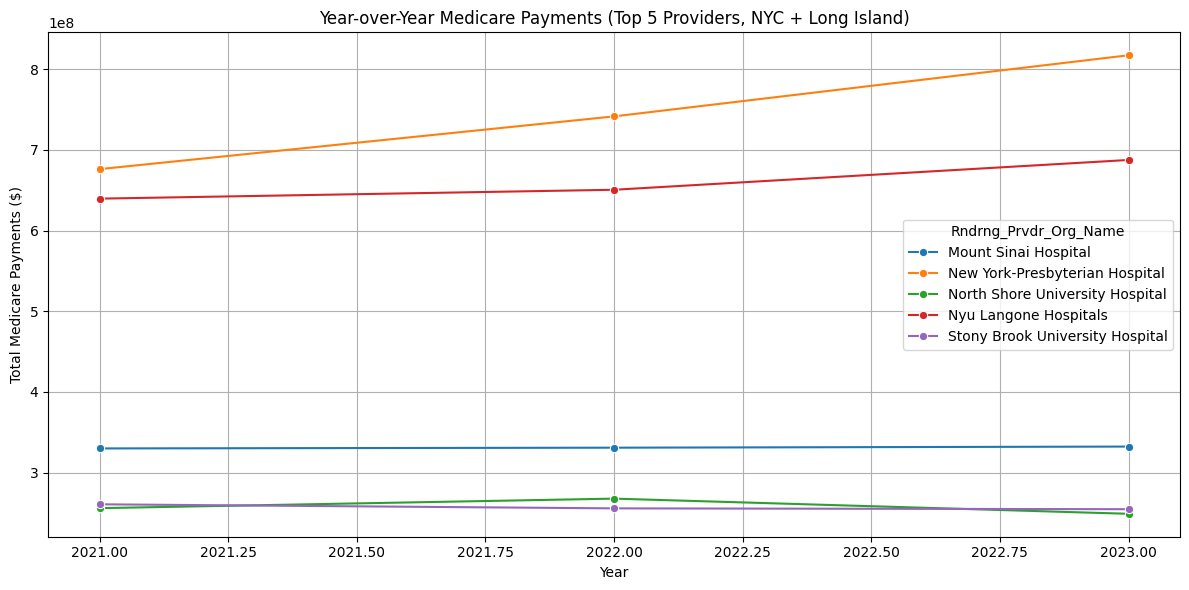

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Upload the Excel file (Colab will prompt upload dialog)
from google.colab import files
uploaded = files.upload()

# Load your Excel file (replace with exact name if different)
df = pd.read_excel("CapstoneProject.xlsx", sheet_name="Sheet1")

# --- CLEANING ---
df.columns = df.columns.str.strip().str.replace(" ", "_").str.replace("-", "_")
numeric_cols = ['Tot_Dschrgs', 'Avg_Submtd_Cvrd_Chrg', 'Avg_Tot_Pymt_Amt', 'Avg_Mdcr_Pymt_Amt']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
df.dropna(subset=['Tot_Dschrgs', 'Avg_Mdcr_Pymt_Amt'], inplace=True)
df.drop_duplicates(inplace=True)

# Calculate total Medicare payments
df['Total_Medicare_Payments'] = df['Tot_Dschrgs'] * df['Avg_Mdcr_Pymt_Amt']

# --- FILTERING NYC + LONG ISLAND ---
nyc_boroughs = {"NEW YORK", "BRONX", "KINGS", "QUEENS", "RICHMOND"}
df_filtered = df[
df['Rndrng_Prvdr_City'].str.upper().isin(nyc_boroughs) |
df['Rndrng_Prvdr_Zip5'].astype(str).str.startswith('11')
].copy()

# Use lowercase 'year' field
df_filtered['year'] = pd.to_numeric(df_filtered['year'], errors='coerce')

# --- TOP 5 PROVIDERS TREND DATA ---
top_5_providers = (
df_filtered.groupby('Rndrng_Prvdr_Org_Name')['Total_Medicare_Payments']
.sum()
.nlargest(5)
.index
)
top_5_df = df_filtered[df_filtered['Rndrng_Prvdr_Org_Name'].isin(top_5_providers)]

trend_data = (
top_5_df.groupby(['year', 'Rndrng_Prvdr_Org_Name'])['Total_Medicare_Payments']
.sum()
.reset_index()
)

# --- TREND LINE PLOT ---
plt.figure(figsize=(12, 6))
sns.lineplot(
data=trend_data,
x='year',
y='Total_Medicare_Payments',
hue='Rndrng_Prvdr_Org_Name',
marker='o'
)
plt.title("Year-over-Year Medicare Payments (Top 5 Providers, NYC + Long Island)")
plt.xlabel("Year")
plt.ylabel("Total Medicare Payments ($)")
plt.grid(True)
plt.tight_layout()
plt.show()

Saving CapstoneProject.xlsx to CapstoneProject (1).xlsx


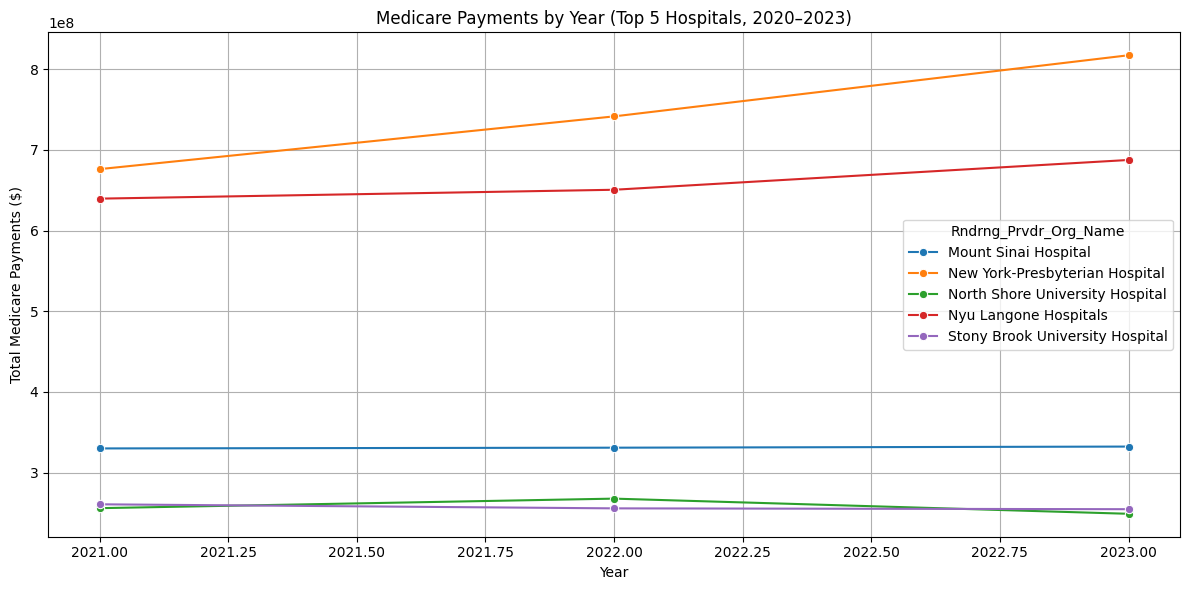

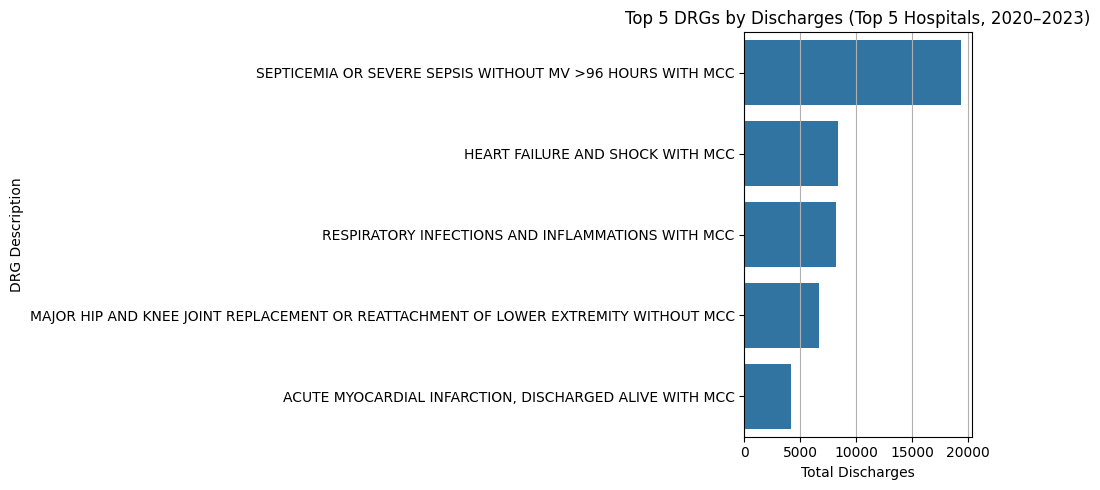

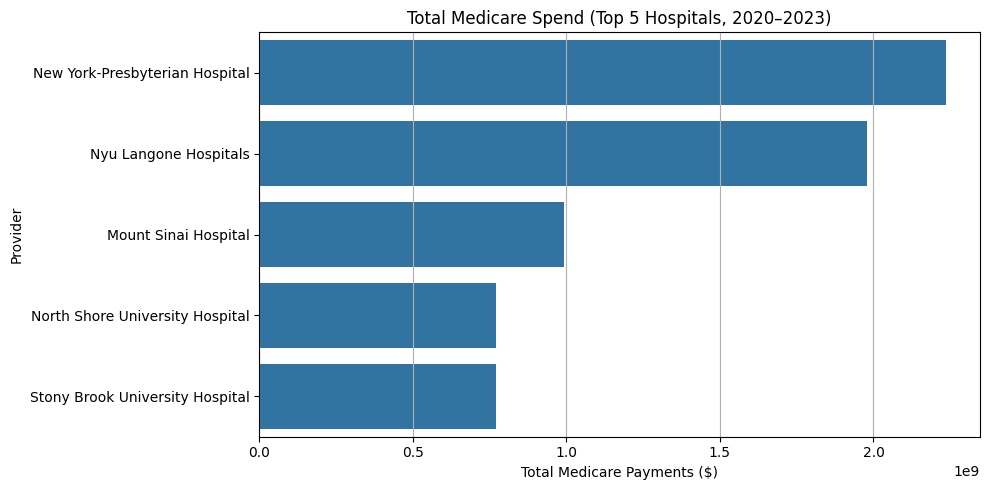

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Upload your file
uploaded = files.upload()

# Load the Excel file
df = pd.read_excel("CapstoneProject.xlsx", sheet_name="Sheet1")

# --- CLEANING ---
df.columns = df.columns.str.strip().str.replace(" ", "_").str.replace("-", "_")
numeric_cols = ['Tot_Dschrgs', 'Avg_Submtd_Cvrd_Chrg', 'Avg_Tot_Pymt_Amt', 'Avg_Mdcr_Pymt_Amt']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
df.dropna(subset=['Tot_Dschrgs', 'Avg_Mdcr_Pymt_Amt'], inplace=True)
df.drop_duplicates(inplace=True)

# Calculate total Medicare payments
df['Total_Medicare_Payments'] = df['Tot_Dschrgs'] * df['Avg_Mdcr_Pymt_Amt']

# Filter to NYC + Long Island
nyc_boroughs = {"NEW YORK", "BRONX", "KINGS", "QUEENS", "RICHMOND"}
df = df[
df['Rndrng_Prvdr_City'].str.upper().isin(nyc_boroughs) |
df['Rndrng_Prvdr_Zip5'].astype(str).str.startswith('11')
].copy()

# Ensure year is numeric
df['year'] = pd.to_numeric(df['year'], errors='coerce')

# Filter for years 2020–2023
df = df[df['year'].between(2020, 2023)]

# --- TOP 5 HOSPITALS OVERALL ---
top_5_hospitals = (
df.groupby('Rndrng_Prvdr_Org_Name')['Total_Medicare_Payments']
.sum()
.nlargest(5)
.index
)
df_top5 = df[df['Rndrng_Prvdr_Org_Name'].isin(top_5_hospitals)]

# --- VISUAL 1: TREND LINE FOR TOP 5 HOSPITALS ---
trend_data = (
df_top5.groupby(['year', 'Rndrng_Prvdr_Org_Name'])['Total_Medicare_Payments']
.sum()
.reset_index()
)

plt.figure(figsize=(12, 6))
sns.lineplot(
data=trend_data,
x='year',
y='Total_Medicare_Payments',
hue='Rndrng_Prvdr_Org_Name',
marker='o'
)
plt.title("Medicare Payments by Year (Top 5 Hospitals, 2020–2023)")
plt.xlabel("Year")
plt.ylabel("Total Medicare Payments ($)")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- VISUAL 2: TOP 5 DRGs BY DISCHARGES FOR TOP 5 HOSPITALS ---
top_drg_data = (
df_top5.groupby('DRG_Desc')['Tot_Dschrgs']
.sum()
.reset_index()
.sort_values(by='Tot_Dschrgs', ascending=False)
.head(5)
)

plt.figure(figsize=(10, 5))
sns.barplot(
data=top_drg_data,
y='DRG_Desc',
x='Tot_Dschrgs'
)
plt.title("Top 5 DRGs by Discharges (Top 5 Hospitals, 2020–2023)")
plt.xlabel("Total Discharges")
plt.ylabel("DRG Description")
plt.tight_layout()
plt.grid(True, axis='x')
plt.show()

# --- VISUAL 3: BAR CHART OF TOTAL SPEND FOR TOP 5 HOSPITALS ---
spend_data = (
df_top5.groupby('Rndrng_Prvdr_Org_Name')['Total_Medicare_Payments']
.sum()
.reset_index()
.sort_values(by='Total_Medicare_Payments', ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(
data=spend_data,
y='Rndrng_Prvdr_Org_Name',
x='Total_Medicare_Payments'
)
plt.title("Total Medicare Spend (Top 5 Hospitals, 2020–2023)")
plt.xlabel("Total Medicare Payments ($)")
plt.ylabel("Provider")
plt.tight_layout()
plt.grid(True, axis='x')
plt.show()